In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

In [2]:
# Initialize the CNN
model = Sequential()

# Add convolutional layers with padding
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3), padding='same'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(2, 2))

# Flatten the layers
model.add(Flatten())

# Add fully connected layers
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))  # 4 classes: cars, trucks, bicycles, bus

# Compile the model
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 150, 150, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 75, 75, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 75, 75, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 37, 37, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 37, 37, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 18, 18, 128)       0

In [3]:
# ImageDataGenerator to preprocess and augment training data
train_datagen = ImageDataGenerator( rescale=1./255,
                                    rotation_range=20,
                                    width_shift_range=0.2,
                                    height_shift_range=0.2,
                                    shear_range=0.2,
                                    zoom_range=0.2,
                                    horizontal_flip=True,
                                    validation_split=0.2  # 20% validation split
                                  )
# Load training and validation data
train_generator = train_datagen.flow_from_directory('C:/Users/User/Desktop/Signal and Image Processing/Group Project/datasetMod/trainMod',
                                                    target_size=(150, 150),
                                                    batch_size=32,
                                                    class_mode='categorical',
                                                    subset='training')  # set as training data

validation_generator = train_datagen.flow_from_directory('C:/Users/User/Desktop/Signal and Image Processing/Group Project/datasetMod/validationMod',
                                                         target_size=(150, 150),
                                                         batch_size=32,
                                                         class_mode='categorical',
                                                         subset='validation')  # set as validation data


Found 3100 images belonging to 4 classes.
Found 105 images belonging to 4 classes.


In [4]:
# Train the model
history = model.fit(train_generator,
                    steps_per_epoch=train_generator.samples // 32,
                    epochs=33,
                    validation_data=validation_generator,
                    validation_steps=validation_generator.samples // 32)


Epoch 1/33
96/96 [==============================] - 80s 824ms/step - loss: 1.3841 - accuracy: 0.3237 - val_loss: 1.3352 - val_accuracy: 0.4792
Epoch 2/33
96/96 [==============================] - 77s 805ms/step - loss: 1.2615 - accuracy: 0.4247 - val_loss: 1.1958 - val_accuracy: 0.4688
Epoch 3/33
96/96 [==============================] - 77s 803ms/step - loss: 1.1518 - accuracy: 0.5010 - val_loss: 1.1020 - val_accuracy: 0.5208
Epoch 4/33
96/96 [==============================] - 84s 872ms/step - loss: 1.0652 - accuracy: 0.5473 - val_loss: 1.0159 - val_accuracy: 0.5625
Epoch 5/33
96/96 [==============================] - 78s 804ms/step - loss: 1.0130 - accuracy: 0.5815 - val_loss: 0.9601 - val_accuracy: 0.6042
Epoch 6/33
96/96 [==============================] - 75s 779ms/step - loss: 0.9380 - accuracy: 0.6098 - val_loss: 0.9016 - val_accuracy: 0.6146
Epoch 7/33
96/96 [==============================] - 74s 773ms/step - loss: 0.8774 - accuracy: 0.6343 - val_loss: 0.8896 - val_accuracy: 0.6354

In [5]:
# Define the test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Rescale pixel values to [0, 1]

# Load test data
test_generator = test_datagen.flow_from_directory('C:/Users/User/Desktop/Signal and Image Processing/Group Project/dataset/testMod',
                                                  target_size=(150, 150),
                                                  batch_size=32,
                                                  class_mode='categorical')

# Evaluate the model on the test data
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc}")


Found 526 images belonging to 4 classes.
17/17 [==============================] - 3s 165ms/step - loss: 0.5222 - accuracy: 0.8099
Test Accuracy: 0.8098859190940857


In [6]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Load and preprocess a new image (replace 'path_to_new_image.jpg' with the path to your image)
new_image_path = 'C:/Users/User/Pictures/slideshow/86.jpg'
img = image.load_img(new_image_path, target_size=(150, 150))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
img_array /= 255.0  # Normalize pixel values

# Make predictions
predictions = model.predict(img_array)
predicted_class = np.argmax(predictions)

# Map predicted class index to class label
class_labels = ['cars', 'trucks', 'bicycles', 'bus']
predicted_label = class_labels[predicted_class]

print(f"Predicted Class: {predicted_label}")

1/1 [==============================] - 0s 115ms/step
Predicted Class: cars


In [7]:
y_true = test_generator.classes
y_pred = np.argmax(model.predict(test_generator), axis=-1)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

17/17 [==============================] - 3s 152ms/step
Classification Report:
              precision    recall  f1-score   support

        cars       0.37      0.39      0.38       180
      trucks       0.19      0.14      0.16       107
    bicycles       0.28      0.27      0.28       139
         bus       0.14      0.17      0.16       100

    accuracy                           0.27       526
   macro avg       0.24      0.24      0.24       526
weighted avg       0.26      0.27      0.26       526



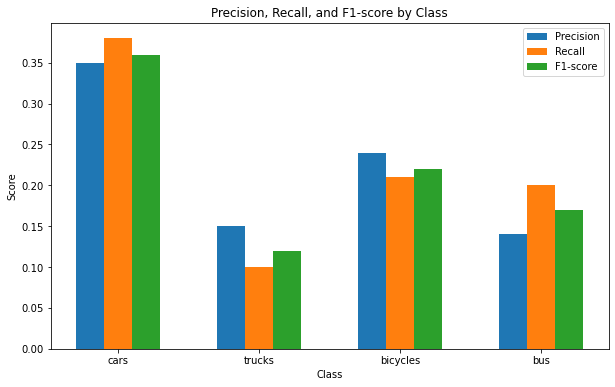

In [8]:
# Define class labels (replace with your class labels)
class_labels = ['cars', 'trucks', 'bicycles', 'bus']

# Define precision, recall, and F1-score arrays from the classification report
precision = [0.35, 0.15, 0.24, 0.14]  # Example precision values
recall = [0.38, 0.10, 0.21, 0.20]      # Example recall values
f1_score = [0.36, 0.12, 0.22, 0.17]    # Example F1-score values

# Plot precision, recall, and F1-score for each class
fig, ax = plt.subplots(figsize=(10, 6))

index = np.arange(len(class_labels))
bar_width = 0.2

# Plot bars for precision, recall, and F1-score
bar1 = ax.bar(index, precision, bar_width, label='Precision')
bar2 = ax.bar(index + bar_width, recall, bar_width, label='Recall')
bar3 = ax.bar(index + 2 * bar_width, f1_score, bar_width, label='F1-score')

# Add labels, title, and legend
ax.set_xlabel('Class')
ax.set_ylabel('Score')
ax.set_title('Precision, Recall, and F1-score by Class')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(class_labels)
ax.legend()

# Show plot
plt.show()

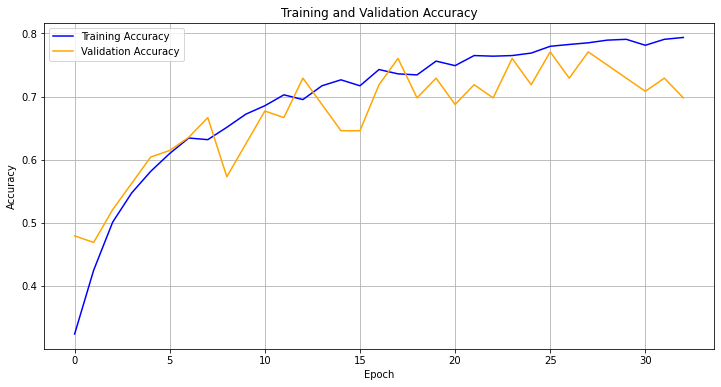

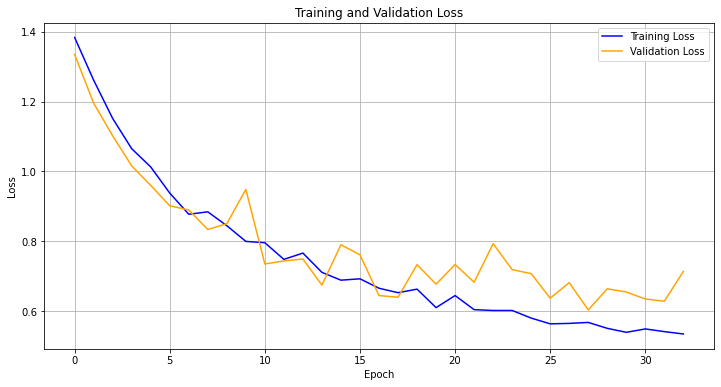

In [9]:
import matplotlib.pyplot as plt

# Extract training history from the model training process
history_dict = history.history

# Plot training and validation accuracy
plt.figure(figsize=(12, 6))
plt.plot(history_dict['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(12, 6))
plt.plot(history_dict['loss'], label='Training Loss', color='blue')
plt.plot(history_dict['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()
